# **ML4_Classification problems. Проблемы классификации.**

### ***1. Download data from Don’tGetKicked competition.***

***Загрузите данные соревнования "Don’tGetKicked"***

Перед началом выполнения  проекта установите все необходимые библиотеки, выполнив 
`pip install -r requirements.txt`

**IMPORT LIBRARIES. ИМПОРТ БИБЛИОТЕК.**

In [4]:
%load_ext autoreload
%autoreload 2
import pickle
import timeit
import os
import pandas as pd
import numpy as np
import ml_utils
from sklearn.preprocessing import OneHotEncoder
from category_encoders import CountEncoder
from sklearn.preprocessing import StandardScaler
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Загрузка данных соревнования выполнена через скрипт `src/download_competition_data.py`. 
Датасет `DontGetKicked` скачан, автоматически распакован и сохранен локально в директорию `./datasets/`.

In [5]:
train_path = "../datasets/training.csv"
test_path = "../datasets/test.csv"

if os.path.exists(train_path) and os.path.exists(test_path):
    data_train = pd.read_csv(train_path)
    data_test = pd.read_csv(test_path)

    print("Данные успешно загружены локально!")
    print(f"Строк и признаков в Train: {data_train.shape}")
    print(f"Строк и признаков в Test: {data_test.shape}")
else:
    print("Ошибка: Файлы датасета не найдены по указанному пути!")
    print(
        f"Пожалуйста, проверьте наличие файлов в папке: {os.path.abspath('./datasets')}"
    )

Данные успешно загружены локально!
Строк и признаков в Train: (72983, 34)
Строк и признаков в Test: (48707, 33)


In [6]:
data_train.head()

,RefId,IsBadBuy,PurchDate,Auction,VehYear,VehicleAge,Make,Model,Trim,SubModel,...,MMRCurrentRetailAveragePrice,MMRCurrentRetailCleanPrice,PRIMEUNIT,AUCGUART,BYRNO,VNZIP1,VNST,VehBCost,IsOnlineSale,WarrantyCost
0,1,0,12/7/2009,ADESA,2006,3,MAZDA,MAZDA3,i,4D SEDAN I,...,11597.0,12409.0,NaN,NaN,21973,33619,FL,7100.0,0,1113
1,2,0,12/7/2009,ADESA,2004,5,DODGE,1500 RAM PICKUP 2WD,ST,QUAD CAB 4.7L SLT,...,11374.0,12791.0,NaN,NaN,19638,33619,FL,7600.0,0,1053
2,3,0,12/7/2009,ADESA,2005,4,DODGE,STRATUS V6,SXT,4D SEDAN SXT FFV,...,7146.0,8702.0,NaN,NaN,19638,33619,FL,4900.0,0,1389
3,4,0,12/7/2009,ADESA,2004,5,DODGE,NEON,SXT,4D SEDAN,...,4375.0,5518.0,NaN,NaN,19638,33619,FL,4100.0,0,630
4,5,0,12/7/2009,ADESA,2005,4,FORD,FOCUS,ZX3,2D COUPE ZX3,...,6739.0,7911.0,NaN,NaN,19638,33619,FL,4000.0,0,1020


In [7]:
# таргет
# data_train[["IsBadBuy"]]

#### ***2. Design the train/validation/test split. Use the "PurchDate" field for the split, test must be later than validation, same for validation and train: train.PurchDate < valid.PurchDate < test.PurchDate. Use the first 1/3 of dates for the train, the last 1/3 of dates for the test, and the middle 1/3 for the validation set. Don’t use the test dataset until the end!***

*Разработай схему разбиения данных на обучающую, валидационную и тестовую выборки. Для разделения используй поле «PurchDate». Тестовая выборка должна хронологически следовать за валидационной, а валидационная - за обучающей, что выражается строгим неравенством: train.PurchDate < valid.PurchDate < test.PurchDate. Выдели первую треть (1/3) хронологического периода под обучающий набор, последнюю треть (1/3) - под тестовый, а среднюю треть - под валидационный. Помни, что тестовый датасет должен оставаться полностью изолированным вплоть до финального тестирования модели!*


In [8]:
data_train["PurchDate"].dtype

<StringDtype(storage='python', na_value=nan)>

In [9]:
data_train["PurchDate"] = pd.to_datetime(data_train["PurchDate"])
data_train["PurchDate"].dtype

dtype('<M8[us]')

In [10]:
print(
    f"В колонке 'PurchDate' хранятся данные в формате {data_train['PurchDate'].dtype}"
)

В колонке 'PurchDate' хранятся данные в формате datetime64[us]


In [11]:
print(
    f"Минимальная дата в датасете: {data_train['PurchDate'].min().strftime('%Y-%m-%d')}"
)
print(
    f"Максимальная дата в датасете: {data_train['PurchDate'].max().strftime('%Y-%m-%d')}"
)

Минимальная дата в датасете: 2009-01-05
Максимальная дата в датасете: 2010-12-30


In [12]:
data_train = data_train.sort_values(by="PurchDate").reset_index(drop=True)

rows_num = len(data_train)
part = rows_num // 3

In [13]:
part

24327

In [14]:
validation_date_cutoff = data_train.iloc[part]["PurchDate"]
validation_date_cutoff

Timestamp('2009-09-15 00:00:00')

In [15]:
test_date_cutoff = data_train.iloc[part * 2]["PurchDate"]
test_date_cutoff

Timestamp('2010-05-14 00:00:00')

In [16]:
train_split, valid_split, test_split = ml_utils.date_trisect(
    df=data_train,
    date_column="PurchDate",
    validation_date=validation_date_cutoff,
    test_date=test_date_cutoff,
)

print("Временной сплит:")
print(
    f"Train: {train_split.shape} | {train_split['PurchDate'].min().strftime('%Y-%m-%d')} - {train_split['PurchDate'].max().strftime('%Y-%m-%d')}"
)
print(
    f"Valid: {valid_split.shape} | {valid_split['PurchDate'].min().strftime('%Y-%m-%d')} - {valid_split['PurchDate'].max().strftime('%Y-%m-%d')}"
)
print(
    f"Test:  {test_split.shape} | {test_split['PurchDate'].min().strftime('%Y-%m-%d')} - {test_split['PurchDate'].max().strftime('%Y-%m-%d')}"
)

Временной сплит:
Train: (24232, 34) | 2009-01-05 - 2009-09-14
Valid: (24414, 34) | 2009-09-15 - 2010-05-13
Test:  (24337, 34) | 2010-05-14 - 2010-12-30


In [17]:
missing_count = train_split.isna().sum()
missing_percent = (train_split.isna().sum() / len(train_split)) * 100

missing_df = pd.concat(
    [missing_count, missing_percent], axis=1, keys=["Всего пропусков", "% пропусков"]
)

missing_df = missing_df[missing_df["Всего пропусков"] > 0].sort_values(
    by="% пропусков", ascending=False
)

print(f"Всего признаков с пропусками: {len(missing_df)}")
missing_df

Всего признаков с пропусками: 16


,Всего пропусков,% пропусков
AUCGUART,24230,99.991746
PRIMEUNIT,24230,99.991746
WheelType,920,3.796633
WheelTypeID,920,3.796633
Trim,721,2.975404
MMRCurrentAuctionCleanPrice,260,1.072961
MMRCurrentAuctionAveragePrice,260,1.072961
MMRCurrentRetailCleanPrice,260,1.072961
MMRCurrentRetailAveragePrice,260,1.072961
SubModel,8,0.033014


In [18]:
# проверяю долю пропусков в проблемных колонках по всем трем выборкам для контроля сдвига данных
for col in ["AUCGUART", "PRIMEUNIT"]:
    pct_train = train_split[col].isna().mean() * 100
    pct_valid = valid_split[col].isna().mean() * 100
    pct_test = test_split[col].isna().mean() * 100
    print(
        f"доля пропусков для '{col}': train = {pct_train:.2f}%, valid = {pct_valid:.2f}%, test = {pct_test:.2f}%"
    )

доля пропусков для 'AUCGUART': train = 99.99%, valid = 99.95%, test = 86.01%
доля пропусков для 'PRIMEUNIT': train = 99.99%, valid = 99.95%, test = 86.01%


***Анализ пропусков в выборках показал, что признаки **AUCGUART** и **PRIMEUNIT** практически отсутствуют в Train и Validation (более 99.9%), однако в Test доля пропусков снижается до 86.01%. Несмотря на появление данных в будущем, я считаю необходимым удалить эти колонки, так как модель физически не сможет обучиться на пустом тренировочном множестве.***

In [19]:
train_split["WheelTypeID"].dtype

dtype('float64')

In [20]:
train_split["WheelType"].dtype

<StringDtype(storage='python', na_value=nan)>

In [21]:
# проверяю взаимное соответствие текстового признака и его числового идентификатора
# чтобы подтвердить гипотезу о полном дублировании информации
print("сопоставление текстовых категорий и числовых идентификаторов колес:")
print(train_split.groupby(["WheelTypeID", "WheelType"], dropna=False).size())

сопоставление текстовых категорий и числовых идентификаторов колес:
WheelTypeID  WheelType
1.0          Alloy        12506
2.0          Covers       10571
3.0          Special        235
NaN          NaN            920
dtype: int64


***Признаки **WheelType** и **WheelTypeID** имеют идентичное количество отсутствующих значений. Проведенная группировка доказала их стопроцентное взаимное совпадение. Решение об удалении одного из признаков можно сделать по матрицам кореляции***

Поле **RefId** -является уникальным ключом лота в базе данных и не имеет физической взаимосвязи с техническим состоянием автомобиля, его сохранение создает риски выявления ложных закономерностей и переобучения модели.   
*Касательно остальных пропусков: категориальные пропуски обработаются на этапе кодирования, а числовые можно заполнить медианой на этапе построения пайплайна.*
***Для дальнейшего исследования структуры датасета я построю матрицы линейных корреляций Пирсона (для выявления мультиколлинеарности числовых признаков) и критерия Хи-квадрат для оценки статистической связи категориальных факторов с целевой переменной.***

In [22]:
# удаляю неинформативные технические признаки и идентификаторы сразу из всех оригинальных выборок
first_drop = ["RefId", "AUCGUART", "PRIMEUNIT"]
train_split = train_split.drop(columns=first_drop, errors="ignore")
valid_split = valid_split.drop(columns=first_drop, errors="ignore")
test_split = test_split.drop(columns=first_drop, errors="ignore")

# выделяю чистые числовые признаки из обучающего набора для анализа коллинеарности
numeric_analysis_cols = train_split.select_dtypes(include=["number"]).columns.tolist()
if "IsBadBuy" in numeric_analysis_cols:
    numeric_analysis_cols.remove("IsBadBuy")

# рассчитываю матрицу корреляции пирсона для числовых полей
corr_matrix = train_split[numeric_analysis_cols].corr(method="pearson")
corr_pairs = corr_matrix.unstack()
strong_numeric_pairs = corr_pairs[
    (abs(corr_pairs) > 0.90) & (corr_pairs != 1.0)
].drop_duplicates()

print("сильные линейные связи между числовыми признаками (пирсон > 0.90):")
print(strong_numeric_pairs)
print("-" * 70)

сильные линейные связи между числовыми признаками (пирсон > 0.90):
VehYear                            VehicleAge                         -0.999992
MMRAcquisitionAuctionAveragePrice  MMRAcquisitionAuctionCleanPrice     0.992078
                                   MMRAcquisitionRetailAveragePrice    0.999765
                                   MMRAcquisitonRetailCleanPrice       0.991454
                                   MMRCurrentAuctionAveragePrice       0.941902
                                   MMRCurrentAuctionCleanPrice         0.936416
                                   MMRCurrentRetailAveragePrice        0.934541
                                   MMRCurrentRetailCleanPrice          0.930407
MMRAcquisitionAuctionCleanPrice    MMRAcquisitionRetailAveragePrice    0.992428
                                   MMRAcquisitonRetailCleanPrice       0.999806
                                   MMRCurrentAuctionAveragePrice       0.933591
                                   MMRCurrentAuctionC

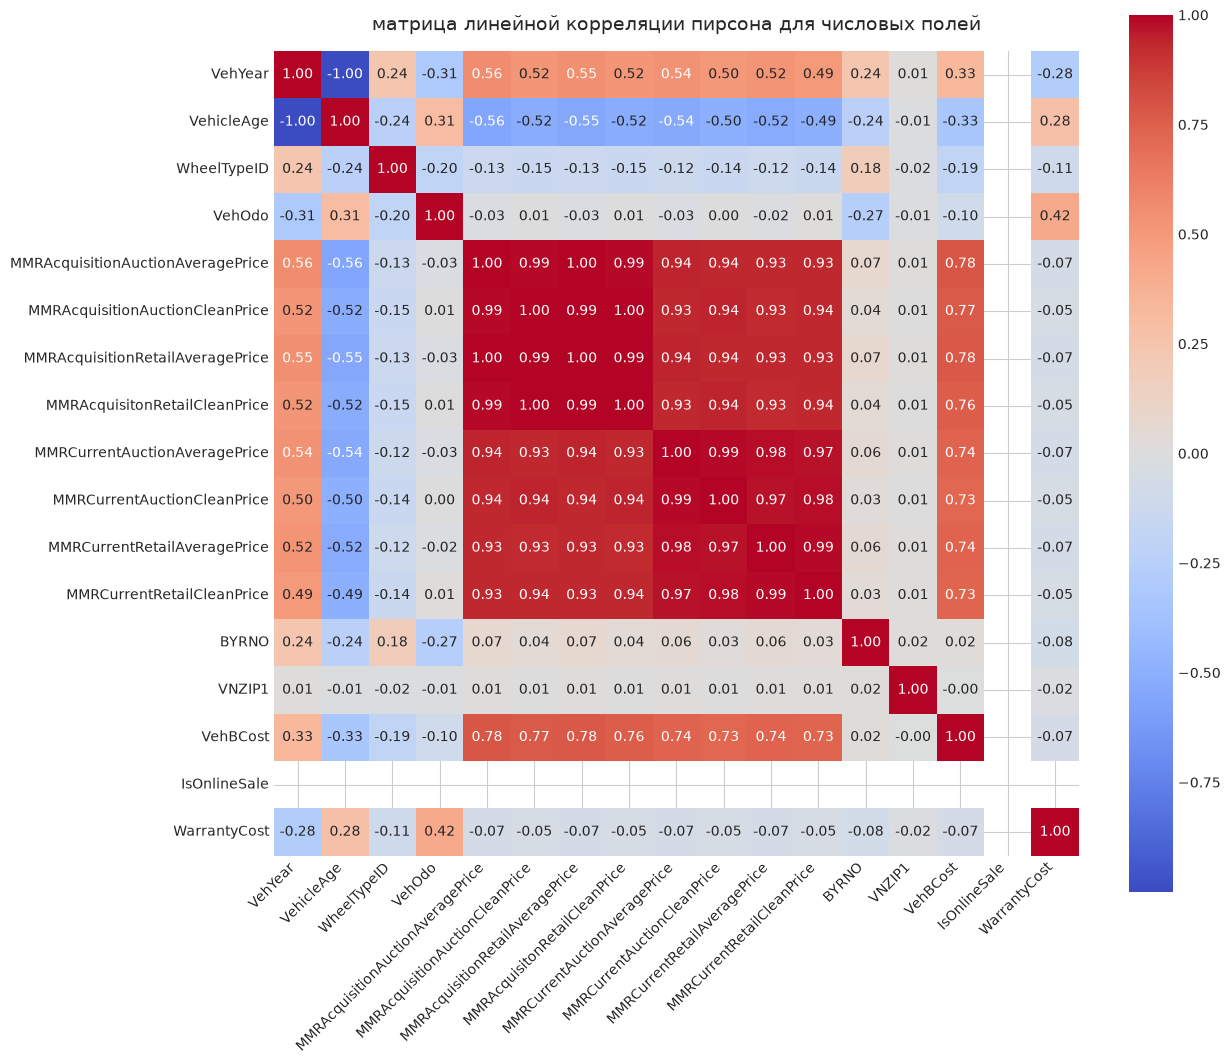

In [23]:
plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(13, 11))

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True)

plt.title("матрица линейной корреляции пирсона для числовых полей", fontsize=14, pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

***Построенная тепловая карта линейной корреляции Пирсона*** выявила критическую мультиколлинеарность в признаковом пространстве. На основе графического анализа видны две ключевые проблемные зоны:

* **Дубликат возраста:** Признаки **VehYear** (год выпуска) и **VehicleAge** (возраст автомобиля) демонстрируют абсолютную отрицательную линейную зависимость, равную почти минус единице. Они несут идентичный физический смысл, так как одно значение напрямую вычисляется из другого. Я принимаю решение полностью исключить из дальнейшей работы **VehYear**, оставляя более интерпретируемый для анализа рисков признак возраста машины.
* **Экстремальная коллинеарность группы цен MMR:** Восемь признаков, описывающих стоимость автомобиля на аукционе, образуют на тепловой карте сплошной сильно скоррелированный блок с коэффициентами от **0.93** до **0.99**. Оставлять всю группу полей в исходном виде нельзя. Для оптимизации геометрии данных я оставляю только две базовые оптовые цены, а остальные шесть колонок (**MMRAcquisitionAuctionCleanPrice**, **MMRAcquisitionRetailAveragePrice**, **MMRAcquisitonRetailCleanPrice**, **MMRCurrentAuctionCleanPrice**, **MMRCurrentRetailAveragePrice**, **MMRCurrentRetailCleanPrice**) полностью удаляю.

**Обоснование отбора конкретных ценовых признаков:**
Сохранение одной цены на момент покупки (**MMRAcquisitionAuctionAveragePrice**) и одной текущей цены (**MMRCurrentAuctionAveragePrice**) позволяет мне полностью сохранить временную динамику изменения стоимости автомобиля. При этом отказ от розничных цен (**Retail**) обоснован спецификой оптовых торгов, где розница является лишь расчетной наценкой. Отказ от цен идеального состояния (**Clean**) продиктован тем, что они линейно дублируют среднее состояние (**Average**), которое является наиболее стабильным и репрезентативным индикатором для подержанных автомобилей.

In [24]:
categorical_analysis_cols = train_split.select_dtypes(
    include=["object", "string"]
).columns.tolist()

print("analys связи категориальных признаков с таргетом IsBadBuy (хи-квадрат):")

for col in categorical_analysis_cols:
    # строю таблицу сопряженности между текстовым признаком и целевой переменной
    contingency_table = pd.crosstab(train_split[col], train_split["IsBadBuy"])

    # провожу статистический тест хи-квадрат
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    # если p-value больше пяти процентов, признак считается статистически независимым от таргета
    if float(p_value) > 0.05:
        print(
            f"-> признак '{col}' независим от таргета (p-value: {float(p_value):.4f}) — кандидат на удаление!"
        )
    else:
        print(
            f"   признак '{col}' имеет значимую связь с таргетом (p-value: {float(p_value):.4e})"
        )

analys связи категориальных признаков с таргетом IsBadBuy (хи-квадрат):
   признак 'Auction' имеет значимую связь с таргетом (p-value: 2.1101e-22)
   признак 'Make' имеет значимую связь с таргетом (p-value: 1.2733e-30)
   признак 'Model' имеет значимую связь с таргетом (p-value: 7.9073e-85)
   признак 'Trim' имеет значимую связь с таргетом (p-value: 6.4653e-29)
   признак 'SubModel' имеет значимую связь с таргетом (p-value: 4.9849e-48)
   признак 'Color' имеет значимую связь с таргетом (p-value: 3.1259e-03)
-> признак 'Transmission' независим от таргета (p-value: 0.4777) — кандидат на удаление!
   признак 'WheelType' имеет значимую связь с таргетом (p-value: 3.3771e-10)
   признак 'Nationality' имеет значимую связь с таргетом (p-value: 2.1283e-02)
   признак 'Size' имеет значимую связь с таргетом (p-value: 1.2247e-16)
   признак 'TopThreeAmericanName' имеет значимую связь с таргетом (p-value: 1.7534e-23)
   признак 'VNST' имеет значимую связь с таргетом (p-value: 5.4288e-13)


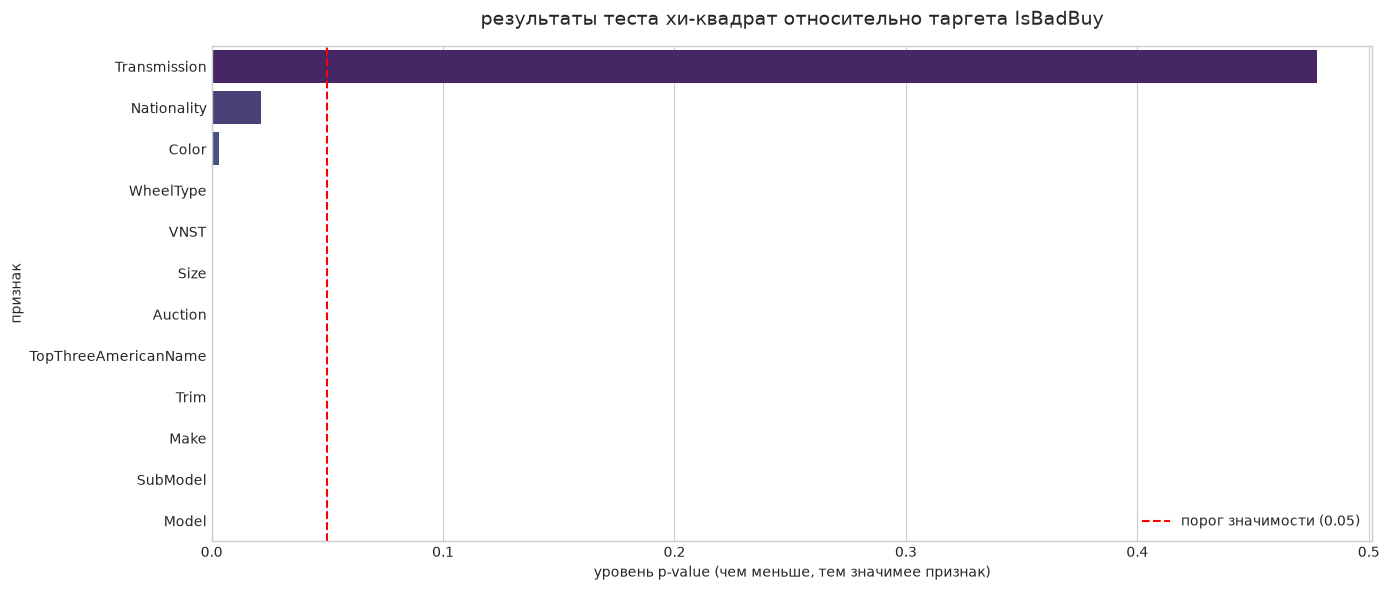

In [25]:
chi2_summary = []
for col in categorical_analysis_cols:
    contingency_table = pd.crosstab(train_split[col], train_split["IsBadBuy"])
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)
    chi2_summary.append({"признак": col, "p_value": float(p_value)})

chi2_df = pd.DataFrame(chi2_summary).sort_values(by="p_value", ascending=False)

plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(14, 6))

sns.barplot(
    x="p_value",
    y="признак",
    data=chi2_df,
    palette="viridis",
    hue="признак",
    legend=False,
)

plt.axvline(x=0.05, color="red", linestyle="--", label="порог значимости (0.05)")
plt.title(
    "результаты теста хи-квадрат относительно таргета IsBadBuy", fontsize=14, pad=15
)
plt.xlabel("уровень p-value (чем меньше, тем значимее признак)")
plt.legend()
plt.tight_layout()
plt.show()

***Анализ результатов критерия Хи-квадрат и отбор категориальных признаков***  
Столбчатая диаграмма уровней значимости p-value наглядно демонстрирует характер связи категориальных факторов с целевой переменной **IsBadBuy**. По результатам проведенного статистического теста я делаю следующие аналитические выводы:

* **Статистически независимый шум:** Признак типа коробки передач **Transmission** оказался единственным фактором, который на графике ушел далеко вправо, значительно превысив критический порог значимости в пять процентов (его p-value составляет почти сорок восемь процентов). Это строго доказывает, что пропорция проблемных автомобилей среди машин с автоматической и механической коробкой передач абсолютно одинакова, и данный признак распределен случайным образом. Я полностью исключаю **Transmission** из пайплайна, так как его сохранение приведет лишь к переобучению модели на шуме.
* **Высокая значимость остальных факторов:** Все остальные одиннадцать категориальных признаков, включая марку, модель, комплектацию и даже цвет автомобиля, находятся в левой части графика и прижаты практически к нулевой отметке p-value. Это подтверждает их колоссальную статистическую важность для предсказания брака.

**Итог по числовому дубликату колес:**
На основе проведенного Хи-квадрат анализа текстовый признак **WheelType** подтвердил свою высокую значимость. Вкупе с ранее проведенной проверкой группировкой, которая доказала стопроцентную идентичность текстового описания и числового идентификатора **WheelTypeID**, я вижу необходимость удаления числового дубликата **WheelTypeID** из проекта.

In [26]:
second_drop = [
    "VehYear",
    "Transmission",
    "WheelTypeID",
    "MMRAcquisitionAuctionCleanPrice",
    "MMRAcquisitionRetailAveragePrice",
    "MMRAcquisitonRetailCleanPrice",
    "MMRCurrentAuctionCleanPrice",
    "MMRCurrentRetailAveragePrice",
    "MMRCurrentRetailCleanPrice",
]

# удаляю выбранные избыточные столбцы из всех оригинальных выборок для синхронизации признаков
train_split = train_split.drop(columns=second_drop, errors="ignore")
valid_split = valid_split.drop(columns=second_drop, errors="ignore")
test_split = test_split.drop(columns=second_drop, errors="ignore")

print(
    " Размерности датафреймов после очистки признакового пространства на основе графиков:"
)
print(f"train: {train_split.shape}")
print(f"valid: {valid_split.shape}")
print(f"test:  {test_split.shape}")

 Размерности датафреймов после очистки признакового пространства на основе графиков:
train: (24232, 22)
valid: (24414, 22)
test:  (24337, 22)


#### ***3. Use LabelEncoder or OneHotEncoder from sklearn to preprocess categorical variables. Be careful with data leakage (fit Encoder to training and apply to validation & test). Consider another coding approach if you encounter new categorical values in validation & test (not seen in training): https://contrib.scikit-learn.org/category_encoders/count.html***


 *Используй LabelEncoder или OneHotEncoder из библиотеки sklearn для предобработки категориальных признаков. Избегай утечки данных: настраивай энкодер (fit) исключительно на обучающей выборке, а валидационный и тестовый наборы только трансформируй (transform). Рассмотри альтернативный подход к кодированию, если столкнешься с новыми уникальными значениями категорий в валидационной и тестовой выборках (которые отсутствовали в обучении): scikit-learn.org*


In [27]:
categorical_cols = train_split.select_dtypes(
    include=["object", "string"]
).columns.tolist()

print(f"Найдено категориальных признаков: {len(categorical_cols)}")
print("Список категориальных колонок:")
print(categorical_cols)

Найдено категориальных признаков: 11
Список категориальных колонок:
['Auction', 'Make', 'Model', 'Trim', 'SubModel', 'Color', 'WheelType', 'Nationality', 'Size', 'TopThreeAmericanName', 'VNST']


In [28]:
# Инициализирую стандартный OneHotEncoder без защиты от неизвестных категорий
# sparse_output=False отключает разреженное хранение, скрывающее нули в памяти компьютера, чтобы можно было визуально оценить матрицу из нулей и единиц.
ohe_base = OneHotEncoder(sparse_output=False, dtype=int)

try:
    ohe_base.fit(train_split[categorical_cols])
    print("Применение OHE к валидационной выборке...")
    valid_ohe_base = ohe_base.transform(valid_split[categorical_cols])

except ValueError as e:
    print(e)

Применение OHE к валидационной выборке...
Found unknown categories ['TOYOTA SCION', 'VOLVO'] in column 1 during transform


*Можно пойти по простому пути и использовать параметр **handle_unknown="ignore** в контрукторе `OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=int)`. В таком случае, если в валидационной или тестовой выборках встретятся категории, которых не было на этапе обучения, энкодер просто проставит нули во все созданные для этого признака столбцы. Новые уникальные значения будут проигнорированы без создания дополнительных колонок, что защитит код от падения с ошибкой **ValueError**, которую словила выше.*

In [29]:
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=int)

ohe.fit(train_split[categorical_cols])

train_ohe = ohe.transform(train_split[categorical_cols])
valid_ohe = ohe.transform(valid_split[categorical_cols])
test_ohe = ohe.transform(test_split[categorical_cols])

print("Результаты кодирования через OneHotEncoder (OHE):")
print(f"Исходное количество категориальных признаков: {len(categorical_cols)}")
print(f"Размерность Train OHE: {train_ohe.shape}")
print(f"Размерность Valid OHE: {valid_ohe.shape}")
print(f"Размерность Test OHE:  {test_ohe.shape}")

Результаты кодирования через OneHotEncoder (OHE):
Исходное количество категориальных признаков: 11
Размерность Train OHE: (24232, 1691)
Размерность Valid OHE: (24414, 1691)
Размерность Test OHE:  (24337, 1691)


Несмотря на то, что использование параметра *handle_unknown="ignore"* защищает OneHotEncoder от падения, следует отказаться от него и перейти к **CountEncoder**, что обусловлено следующим:

* **Устранение взрывного роста признаков:** OneHotEncoder расширяет признаковое пространство до огромных масштабов из-за колонок с высокой мощностью (Model, SubModel). Использование **CountEncoder** позволяет полностью избежать этой проблемы: он кодирует признаки «один в один», сохраняя исходную компактность таблицы и не создавая тысячи разреженных нулевых столбцов. Это снижает нагрузку на оперативную память и защищает будущие модели от переобучения.
* **Сохранение информации о редких категориях:** Когда OneHotEncoder сталкивается с новыми брендами или моделями машин в валидации и тесте (такими как обнаруженные ранее VOLVO или TOYOTA SCION), он полностью их игнориует, расставляя нули для всех остальных брендов из трейна, тем самым теряется уникальность обьекта выборки. **CountEncoder** решает эту проблему кодируя абсолютно все новые, невидимые ранее категории числом **0** (встретились ноль раз на Train). Для алгоритмов на основе деревьев решений (Random Forest, Gradient Boosting) это становится сильным, понятным сигналом о том, что перед нами редкий или уникальный объект.

***Принцип работы частотного кодировщика CountEncoder***:
1. На этапе обучения он сканирует текстовую колонку в тренировочной выборке и подсчитывает, сколько раз конкретное текстовое значение встретилось в данных (вычисляет абсолютную частоту).
2. На этапе трансформации он заменяет текстовую строку на полученное число. Например, если кодируем столбец с моделями машин, то по частотоам будет понятно наколько она редка или обычна, при этом у новых моделей  из валидации или теста будет проставлена частота 0. 

Таким образом, категориальные признаки полностью переводятся в числовой формат без изменения геометрии и объема исходного датасета.

In [30]:
encoder = CountEncoder(cols=categorical_cols, handle_unknown=0)

encoder.fit(train_split)

train_count = encoder.transform(train_split)
valid_count = encoder.transform(valid_split)
test_count = encoder.transform(test_split)

print("Частотное кодирование категориальных признаков успешно завершено:")
print(f"Размерность Train: {train_count[categorical_cols].shape}")
print(f"Размерность Valid: {valid_count[categorical_cols].shape}")
print(f"Размерность Test:  {test_count[categorical_cols].shape}")

Частотное кодирование категориальных признаков успешно завершено:
Размерность Train: (24232, 11)
Размерность Valid: (24414, 11)
Размерность Test:  (24337, 11)


In [31]:
# Нахожу строки в валидационной выборке, где после кодирования модель машины стала равна 0
unknown_models_mask = valid_count["Model"] == 0

# Беру исходные текстовые названия машин и их новые закодированные частоты для сравнения
comparison_df = pd.DataFrame(
    {
        "Исходный текст (оригинал)": valid_split.loc[unknown_models_mask, "Model"],
        "Частотный код (после кодирования)": valid_count.loc[
            unknown_models_mask, "Model"
        ],
    }
)

print(f"Всего в Validation найдено строк с новыми моделями: {len(comparison_df)}")
print("\nПервые несколько строк для визуальной проверки:")

comparison_df.head(5)

Всего в Validation найдено строк с новыми моделями: 4360

Первые несколько строк для визуальной проверки:


,Исходный текст (оригинал),Частотный код (после кодирования)
105,RENDEZVOUS AWD 3.4L,0.0
341,ES300 3.0L V6 EFI DO,0.0
366,SENTRA 2.5L I-4 EFI,0.0
388,MAGNUM V6,0.0
403,GRAND AM V6 3.4L V 6,0.0


In [32]:
target_makes_mask = valid_split["Make"].isin(["VOLVO", "TOYOTA SCION"])

check_df = pd.DataFrame(
    {
        "Марка (Исходный текст)": valid_split.loc[target_makes_mask, "Make"],
        "Модель (Исходный текст)": valid_split.loc[target_makes_mask, "Model"],
        "Код Марки (После кодирования)": valid_count.loc[target_makes_mask, "Make"],
        "Код Модели (После кодирования)": valid_count.loc[target_makes_mask, "Model"],
    }
)

print(f"Найдено строк с VOLVO и TOYOTA SCION в валидационной выборке: {len(check_df)}")
print("\nВывод первых строк для проверки:")
check_df.head(5)

Найдено строк с VOLVO и TOYOTA SCION в валидационной выборке: 10

Вывод первых строк для проверки:


,Марка (Исходный текст),Модель (Исходный текст),Код Марки (После кодирования),Код Модели (После кодирования)
3284,TOYOTA SCION,XA 1.5L I4 EFI,0.0,0.0
18236,VOLVO,S40,0.0,0.0
19508,VOLVO,S40,0.0,0.0
20581,VOLVO,S40,0.0,0.0
20919,VOLVO,S40,0.0,0.0


In [33]:
type(train_count)

pandas.DataFrame

### ***После кодирования нечисловых признаков нужно заполнить числовые пропуски в выборках медианой из train выборки и отмасштабировать признаки StandardScaler'ом.***

In [34]:
# принудительно оборачиваю переменные в конструктор датафрейма для линтера
train_df_clean = pd.DataFrame(train_count)
valid_df_clean = pd.DataFrame(valid_count)
test_df_clean = pd.DataFrame(test_count)

# выделяю все числовые признаки и закодированные частоты, автоматически отсекая дату покупки
# и отсекая таргет
all_features = train_df_clean.select_dtypes(include=["number"]).columns.tolist()
if "IsBadBuy" in all_features:
    all_features.remove("IsBadBuy")


# отдельно фиксирую только исходные числовые колонки для заполнения пропусков медианой
numeric_cols = [col for col in all_features if col not in categorical_cols]
numeric_cols

['VehicleAge',
 'VehOdo',
 'MMRAcquisitionAuctionAveragePrice',
 'MMRCurrentAuctionAveragePrice',
 'BYRNO',
 'VNZIP1',
 'VehBCost',
 'IsOnlineSale',
 'WarrantyCost']

In [35]:
train_scaled = train_df_clean.copy()
valid_scaled = valid_df_clean.copy()
test_scaled = test_df_clean.copy()

# список для  сбора статистики по пропускам
imputation_summary = []

for col in numeric_cols:
    before_train = train_scaled[col].isna().sum()
    before_valid = valid_scaled[col].isna().sum()
    before_test = test_scaled[col].isna().sum()

    # вычисляю медиану строго по обучающей выборке для предотвращения утечки данных
    train_median = train_scaled[col].median()

    # заполняю пропущенные значения во всех выборках этой медианой
    train_scaled[col] = train_scaled[col].fillna(train_median)
    valid_scaled[col] = valid_scaled[col].fillna(train_median)
    test_scaled[col] = test_scaled[col].fillna(train_median)

    if before_train > 0 or before_valid > 0 or before_test > 0:
        imputation_summary.append(
            {
                "признак": col,
                "медиана (train)": train_median,
                "пропуски train (до)": before_train,
                "пропуски train (после)": train_scaled[col].isna().sum(),
                "пропуски valid (до)": before_valid,
                "пропуски valid (после)": valid_scaled[col].isna().sum(),
                "пропуски test (до)": before_test,
                "пропуски test (после)": test_scaled[col].isna().sum(),
            }
        )

imputation_report = pd.DataFrame(imputation_summary)
imputation_report

,признак,медиана (train),пропуски train (до),пропуски train (после),пропуски valid (до),пропуски valid (после),пропуски test (до),пропуски test (после)
0,MMRAcquisitionAuctionAveragePrice,5510.0,3,0,3,0,12,0
1,MMRCurrentAuctionAveragePrice,5576.5,260,0,16,0,39,0


In [36]:
scaler = StandardScaler()

# обучаю стандартизатор сразу на всех признаках обучающей выборки
scaler.fit(train_scaled[all_features])

# масштабирую всю матрицу признаков целиком для всех трех выборок
X_train = pd.DataFrame(
    scaler.transform(train_scaled[all_features]),
    columns=all_features,
    index=train_scaled.index,
)
X_valid = pd.DataFrame(
    scaler.transform(valid_scaled[all_features]),
    columns=all_features,
    index=valid_scaled.index,
)
X_test = pd.DataFrame(
    scaler.transform(test_scaled[all_features]),
    columns=all_features,
    index=test_scaled.index,
)

# выделяю векторы целевой переменной
y_train = train_scaled["IsBadBuy"]
y_valid = valid_scaled["IsBadBuy"]
y_test = test_scaled["IsBadBuy"]

print("Сводка после предобработки и масштабирования всех признаков:")
print(f"Общее число пропусков в X_train: {X_train.isnull().sum().sum()}")
print(f"Общее число пропусков в X_valid: {X_valid.isnull().sum().sum()}")
print(f"Общее число пропусков в X_test: {X_test.isnull().sum().sum()}")
print(f"Размерность обучающей матрицы X_train: {X_train.shape}")


Сводка после предобработки и масштабирования всех признаков:
Общее число пропусков в X_train: 0
Общее число пропусков в X_valid: 0
Общее число пропусков в X_test: 0
Размерность обучающей матрицы X_train: (24232, 20)


#### ***4. Train LogisticRegression, GaussianNB, KNN from sklearn on the training dataset and check the quality of your algorithms on the validation dataset. The dependent variable (IsBadBuy) is binary. Don't forget to normalize your datasets before training your models.***

***You must get at least 0.15 Gini score (the best of all three). Which algorithm performs better? And why?***

*Обучите модели логистической регрессии (LogisticRegression), наивного Байеса (GaussianNB) и k-ближайших соседей (KNN) из библиотеки sklearn на обучающем наборе данных и проверьте качество работы ваших алгоритмов на валидационном наборе данных. Зависимая переменная (IsBadBuy) является бинарной. Не забудьте нормализовать ваши наборы данных перед обучением моделей. Вы должны получить коэффициент Джини (Gini score) не менее 0.15 (для лучшего из всех трех алгоритмов). Какой алгоритм работает лучше? И почему?*

In [37]:
models = {
    "Logistic Regression (sklearn)": LogisticRegression(
        max_iter=2000, solver="saga", random_state=42
    ),
    "Gaussian Naive Bayes (sklearn)": GaussianNB(),
    "K-Nearest Neighbors (sklearn)": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
}

baseline_results = []
preds_dict = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    # получаю вероятности отнесения к положительному классу для расчета площади под кривой
    # столбец 0 хранит вероятность класса 0: не наступит, столбец 1 - вероятность положительного класса 1 (наступит).
    # можно проверить через print(model.classes_) выдаст [0 1], то есть забираю 1-й столбец
    preds_proba = model.predict_proba(X_valid)[:, 1]
    preds_dict[name] = preds_proba

    roc_auc = roc_auc_score(y_valid, preds_proba)
    gini_score = 2 * roc_auc - 1

    baseline_results.append(
        {
            "Алгоритм": name,
            "ROC-AUC": round(roc_auc, 4),
            "Gini Score": round(gini_score, 4),
        }
    )

# свожу результаты эксперимента в красивую сравнительную таблицу
results_df = pd.DataFrame(baseline_results)
results_df

,Алгоритм,ROC-AUC,Gini Score
0,Logistic Regression (sklearn),0.7195,0.4390
1,Gaussian Naive Bayes (sklearn),0.7255,0.4510
2,K-Nearest Neighbors (sklearn),0.6619,0.3238


In [38]:
fig_roc = ml_utils.plot_models_roc_curves(y_valid, preds_dict)
fig_roc.show()

### ***Вывод***

После полной стандартизации признакового пространства (включая закодированные частотные признаки) все три алгоритма из библиотеки **sklearn** успешно обучились без предупреждений о сходимости и уверенно преодолели минимальный порог **Gini score** в **0.15** (изначально скелила только числовые признаки):

* **Gaussian Naive Bayes**: ROC-AUC = **0.7255**, Gini Score = **0.4510** — **лучший результат**
* **Logistic Regression**: ROC-AUC = **0.7195**, Gini Score = **0.4390**
* **K-Nearest Neighbors**: ROC-AUC = **0.6619**, Gini Score = **0.3238**


Наилучший результат у **Gaussian Naive Bayes**, хотя **Logistic Regression** после масштабирования всех признаков вплотную приблизилась к лидеру. Причины такого распределения результатов:

* **Устойчивость наивного Байеса:** Алгоритм оценивает условные плотности вероятности каждого признака независимо друг от друга. Такой генеративный подход выступает естественным регуляризатором и обеспечивает стабильное ранжирование объектов даже при сильном дисбалансе классов.
* **Линейная разделимость и баланс масштабов:** После приведения всех признаков к единому масштабу градиентный спуск **Logistic Regression** корректно сошелся, позволив модели уловить зависимости в ценах и частотах. Небольшое отставание от лидера связано с базовыми настройками L2-регуляризации и отсутствием балансировки весов классов.
* **Ограничения метрического подхода:** Алгоритм **KNN** показал самый низкий результат. В двадцатимерном пространстве признаков с высоким дисбалансом целевой переменной локальные окрестности точек чаще всего заполнены объектами мажоритарного класса (исправными автомобилями), что снижает качество ранжирования редких поломок.

In [39]:
ml_utils.save_metrics_checkpoint(
    df=results_df, my_dict=preds_dict, folder="checkpoints"
)

csv_path = os.path.join("checkpoints", "model_results.csv")
if os.path.exists(csv_path):
    saved_df = pd.read_csv(csv_path)
else:
    saved_df = pd.DataFrame(columns=["Алгоритм", "ROC-AUC", "Gini Score"])

все метрики и словари успешно сохранены в папку 'checkpoints'


In [40]:
pkl_path = os.path.join("checkpoints", "my_models.pkl")

with open(pkl_path, "rb") as f:
    loaded_preds = pickle.load(f)

print("Сохраненные модели:", list(loaded_preds.keys()))

Сохраненные модели: ['Logistic Regression (sklearn)', 'Gaussian Naive Bayes (sklearn)', 'K-Nearest Neighbors (sklearn)']


#### ***5. Implement Gini score calculation. You can use the 2*ROC AUC - 1 approach, so you need to implement the ROC AUC calculation.**
Check if your metric is approximately equal to abs(2*sklearn.metrics.roc_auc_score - 1)

Для расчёта **ROC AUC** предсказанные вероятности (`preds_proba`) сортируются по убыванию, а совпавшие значения  объединяются в общие группы. Двигаясь от точки $(0, 0)$ к $(1, 1)$, для каждой группы вычисляются координаты $(\text{FPR}, \text{TPR})$, после чего итоговая площадь находится суммированием прямоугольных трапеций.

$$\text{ROC AUC} = \sum_{i=1}^{n-1} \frac{\text{TPR}_i + \text{TPR}_{i+1}}{2} \cdot (\text{FPR}_{i+1} - \text{FPR}_i)$$

Для понимания математики расчета кривой ROC AUC и ее значения я использовала [статью Александра Дьяконова](https://alexanderdyakonov.wordpress.com/2017/07/28/auc-roc-%D0%BF%D0%BB%D0%BE%D1%89%D0%B0%D0%B4%D1%8C-%D0%BF%D0%BE%D0%B4-%D0%BA%D1%80%D0%B8%D0%B2%D0%BE%D0%B9-%D0%BE%D1%88%D0%B8%D0%B1%D0%BE%D0%BA/).


In [41]:
fig_trapezoid = ml_utils.plot_roc_trapezoid()
fig_trapezoid.show()

In [42]:
ml_utils.plot_roc_grid_example(
    y_true=np.array([1, 0, 1, 1, 0, 0, 0]),
    preds_proba=np.array([0.9, 0.8, 0.7, 0.6, 0.6, 0.4, 0.2]),
).show()

**Реализация алгоритма:** необходимо отсортировать объекты по убыванию вероятности и шаг за шагом откладывать точки на графике.

* Если класс **1** - шаг вверх (растёт $\text{TPR}$).
* Если класс **0** - шаг вправо (растёт $\text{FPR}$).
* Если вероятности совпали - итоговый шаг является общим вектором перемещения по диагонали (получается прямоугольная трапеция).

На каждом шаге нужно рассчитать площадь очередной трапеции $S_i = \frac{a+b}{2} \cdot h$ и прибавить к общему результату.


In [43]:
def custom_roc_auc_loop(y_true: np.ndarray, preds_proba: np.ndarray) -> float:
    """Вычисляет ROC AUC пошаговым обходом сетки m x n в цикле."""
    # приведение к массивам numpy (сброс индексов)
    y_true = np.asarray(y_true)
    preds_proba = np.asarray(preds_proba)

    if y_true.shape != preds_proba.shape:
        raise ValueError("Размеры y_true и preds_proba должны совпадать.")

    # количество шагов сетки по вертикали  и по горизонтали
    total_pos = int(np.sum(y_true == 1))
    total_neg = int(np.sum(y_true == 0))

    if total_pos == 0 or total_neg == 0:
        raise ValueError("В y_true должны присутствовать оба класса (и 0, и 1).")

    # сортировка объектов по убыванию вероятности
    desc_idx = np.argsort(preds_proba, kind="mergesort")[::-1]
    y_sorted = y_true[desc_idx]
    proba_sorted = preds_proba[desc_idx]

    auc = 0.0
    tp = 0
    fp = 0
    prev_fpr = 0.0
    prev_tpr = 0.0

    n_samples = len(y_sorted)
    i = 0

    # пошаговый проход по отсортированным объектам с группировкой ties
    while i < n_samples:
        current_proba = proba_sorted[i]

        # собираю все объекты с одинаковой вероятностью (один порог)
        while i < n_samples and proba_sorted[i] == current_proba:
            if y_sorted[i] == 1:
                tp += 1
            else:
                fp += 1
            i += 1

        # вычисляю новые координаты на сетке
        curr_fpr = fp / total_neg
        curr_tpr = tp / total_pos

        # прибавляю площадь очередной трапеции: (a + b) / 2 * h
        auc += (prev_tpr + curr_tpr) / 2 * (curr_fpr - prev_fpr)

        # запоминаю текущую точку как начало следующего шага
        prev_fpr = curr_fpr
        prev_tpr = curr_tpr

    return float(auc)

На больших датасетах циклы в Python работают значительно медленнее векторных операций в NumPy. В NumPy тот же самый обход по точкам можно заменить одной операцией над сдвинутыми срезами массива:

* **Левые основания $a$ (`tpr[i]`):** срез `tpr[:-1]` (все точки кривой, кроме последней).
* **Правые основания $b$ (`tpr[i + 1]`):** срез `tpr[1:]` (все точки кривой, кроме первой).
* **Высоты сегментов $h$ (`fpr[i + 1] - fpr[i]`):** функция разности `np.diff(fpr)`.

Ниже реализую векторизованный вариант и сравню скорость работы обоих подходов.

In [44]:
def custom_roc_auc_np(y_true: np.ndarray, preds_proba: np.ndarray):
    """Вычисляет ROC AUC методом трапеций с учётом повторяющихся скоров (ties).
    y_true: Массив истинных бинарных меток классов (0 и 1).
    preds_proba: Массив предсказанных вероятностей положительного класса."""

    y_true = np.asarray(y_true)
    preds_proba = np.asarray(preds_proba)

    if y_true.shape != preds_proba.shape:
        raise ValueError("Размеры y_true и preds_proba должны совпадать.")

    # сортировка по убыванию предсказанной вероятности
    desc_idx = np.argsort(preds_proba, kind="mergesort")[::-1]
    preds_proba = preds_proba[desc_idx]
    y_true = y_true[desc_idx]

    # группировка совпавших значений вероятностей (обработка ties)
    distinct_value_idx = np.where(np.diff(preds_proba))[0]
    threshold_idxs = np.concatenate([distinct_value_idx, [y_true.size - 1]])

    # накопленные TP и FP на каждом уникальном пороге
    tp_sum = np.cumsum(y_true)[threshold_idxs]
    fp_sum = 1 + threshold_idxs - tp_sum

    # + начальная точка (0, 0)
    tp_sum = np.concatenate([[0], tp_sum])
    fp_sum = np.concatenate([[0], fp_sum])

    if fp_sum[-1] == 0 or tp_sum[-1] == 0:
        raise ValueError("В y_true должны присутствовать оба класса (и 0, и 1).")

    # количества в доли (TPR и FPR)
    tpr = tp_sum / tp_sum[-1]
    fpr = fp_sum / fp_sum[-1]

    # Суммируем площади прямоугольных трапеций: S = sum((y1 + y2) / 2 * (x2 - x1))
    trapezoid_areas = (tpr[:-1] + tpr[1:]) / 2 * np.diff(fpr)

    return float(np.sum(trapezoid_areas))

In [45]:
def custom_gini(y_true, preds_proba):
    auc = custom_roc_auc_np(y_true, preds_proba)
    return abs(2 * auc - 1)

#### ***замер разницы в скорости векторной и обычной функций:***

In [46]:
# берём предсказания первой модели из словаря для замера скорости
sample_model = "Logistic Regression (sklearn)"
sample_preds = loaded_preds[sample_model]

assert np.isclose(
    custom_roc_auc_loop(y_valid, sample_preds),
    custom_roc_auc_np(y_valid, sample_preds),
)

n_runs = 100
time_loop = timeit.timeit(
    lambda: custom_roc_auc_loop(y_valid, sample_preds), number=n_runs
)
time_vec = timeit.timeit(
    lambda: custom_roc_auc_np(y_valid, sample_preds), number=n_runs
)

print(f"Выборка: {sample_model} ({len(y_valid)} объектов, {n_runs} запусков)")
print(f"Цикл while/for: {time_loop:.4f} сек.")
print(f"Векторизация:   {time_vec:.4f} сек.")
print(f"Ускорение:      в {time_loop / time_vec:.1f} раз")


Выборка: Logistic Regression (sklearn) (24414 объектов, 100 запусков)
Цикл while/for: 0.9486 сек.
Векторизация:   0.1940 сек.
Ускорение:      в 4.9 раз


*Векторизованная реализация оказалась **в 5 раз быстрее** пошагового цикла. Основную долю времени в обеих функциях занимает сортировка `np.argsort`, которая уже оптимизирована на уровне C. Поэтому на небольших датасетах разница в миллисекундах незаметна, и простой цикл выигрывает за счёт наглядности. Однако при масштабировании до миллионов строк или многократном расчёте метрики внутри кросс-валидации векторизация становится обязательной.*

#### ***Сравнение метрик Джинни от SkLearn и кастомной:***

In [47]:
for name, preds_proba in loaded_preds.items():
    my_gini = custom_gini(y_valid, preds_proba)
    sklearn_gini = abs(2 * roc_auc_score(y_valid, preds_proba) - 1)

    is_equal = np.isclose(my_gini, sklearn_gini)
    print(
        f"{name}: custom={my_gini:.6f} | sklearn={sklearn_gini:.6f} |"
        f" Совпадает: {is_equal}"
    )

Logistic Regression (sklearn): custom=0.438978 | sklearn=0.438978 | Совпадает: True
Gaussian Naive Bayes (sklearn): custom=0.450995 | sklearn=0.450995 | Совпадает: True
K-Nearest Neighbors (sklearn): custom=0.323840 | sklearn=0.323840 | Совпадает: True


#### ***6. Implement your own versions of LogisticRegression, KNN and NaiveBayes classifiers. For LogisticRegression compute gradients with respect to the loss and use stochastic gradient descent. Can you reproduce the results from step 4?***

*Guidance for this task: Your model must be represented by class with methods fit, predict (predict_proba with 0.5 threshold), predict_proba. For LR moder, compute the loss gradient with respect to parameters w and parameter b in the fit function. Use a simple SGD approach to estimate optimal values of parameters.*

***6.1. Реализация алгоритма логистической регрессии (SGD)*** 

**Суть алгоритма:** линейная модель классификации, которая оценивает вероятность принадлежности объекта к классу **1**, пропуская линейную комбинацию признаков $z = \mathbf{w}^T\mathbf{x} + b$ через сигмоиду $\sigma(z) = \frac{1}{1 + e^{-z}}$.

*Модель обучается методом пообъектного стохастического градиентного спуска (SGD). На каждой эпохе выборка перемешивается, а веса $\mathbf{w}$ и свободный член $b$ обновляются в сторону антиградиента функции потерь (Log-Loss):*

$$\nabla_{\mathbf{w}} L = (p_i - y_i)\mathbf{x}_i, \qquad \nabla_{b} L = p_i - y_i$$


In [ ]:
class LogisticRegressionSGD:
    """Логистическая регрессия через стохастический градиентный спуск.
    На каждом шаге используется один случайный объект:
        p_i = sigmoid(x_i · w + b)
        residual = p_i - y_i
        w -= lr_t * residual * x_i
        b -= lr_t * residual
    """

    def __init__(self, lr=0.05, schedule="harmonic", max_epochs=30, random_state=21):
        self.lr = lr  # начальная скорость обучения (размер шага)
        self.schedule = (
            schedule  # стратегия затухания ('const', 'linear', 'exp', 'harmonic')
        )
        self.max_epochs = max_epochs  # количество полных проходов по выборке
        self.random_state = random_state

    @staticmethod
    def _sigmoid(z):
        """Вычисление сигмоиды с защитой от переполнения."""
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    def _learning_rate(self, t, T):
        """Возвращает шаг lr_t для текущего обновления весов.
        t-номер текущей итерации (шага по одному объекту, от 0 до T - 1).
        T-общее количество шагов обучения (max_epochs * n_samples).
        """
        if self.schedule == "const":
            return self.lr
        if self.schedule == "linear":
            return self.lr * max(0.0, 1.0 - t / T)
        if self.schedule == "exp":
            return self.lr * np.exp(-t / T)
        if self.schedule == "harmonic":
            return self.lr / (1.0 + t / T)
        raise ValueError(
            "schedule должен быть одним из: 'const', 'linear', 'exp', 'harmonic'"
        )

    def fit(self, X, y):
        """Обучение модели методом пообъектного SGD."""
        # приведение к массивам numpy (сброс индексов)
        X_arr = np.asarray(X, dtype=float)
        y_arr = np.asarray(y, dtype=float)

        n_samples, n_features = X_arr.shape
        T = self.max_epochs * n_samples
        rng = np.random.default_rng(self.random_state)

        # инициализация весов w и свободного члена b
        self.w = np.zeros(n_features)
        self.b = 0.0
        t = 0

        for _ in range(self.max_epochs):
            for i in rng.permutation(n_samples):
                lr_t = self._learning_rate(t, T)
                x_i = X_arr[i]

                # прямой проход и обновление параметров против градиентов
                p_i = self._sigmoid(x_i @ self.w + self.b)
                residual = p_i - y_arr[i]
                self.w -= lr_t * residual * x_i
                self.b -= lr_t * residual
                t += 1

        return self

    def predict_proba(self, X):
        """Возвращает вероятности классов [P(y=0), P(y=1)]."""
        if not hasattr(self, "w"):
            raise ValueError("Эта модель еще не обучена. Сначала вызовите метод .fit()")

        X_arr = np.asarray(X, dtype=float)
        prob_pos = self._sigmoid(X_arr @ self.w + self.b)
        return np.column_stack([1.0 - prob_pos, prob_pos])

    def predict(self, X, threshold=0.5):
        """Возвращает предсказания классов с порогом 0.5."""
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

***6.2. Наивный байесовский классификатор (GaussianNB)***

**Суть алгоритма:** вероятностный классификатор на основе теоремы Байеса и "наивного" предположения об условной независимости всех признаков внутри каждого класса.

**Как обучается и предсказывает:**
* На этапе `fit` алгоритм без итераций вычисляет доли классов (априорные вероятности $P(y=c)$), а также среднее $\mu_{c,d}$ и дисперсию $\sigma_{c,d}^2$ каждого признака в предположении, что данные распределены нормально $\mathcal{N}(\mu, \sigma^2)$.
* На этапе `predict_proba` для защиты от обнуления произведения малых вероятностей вычисляется сумма логарифма априорной вероятности класса и логарифмов плотностей нормального (гауссовского) распределения признаков:

$$\ln P(y = c) + \sum_{d=1}^{D} \ln p(x_d \mid y = c) = \ln P(y = c) - \frac{1}{2}\sum_{d=1}^{D} \left[ \ln(2\pi \sigma_{c,d}^2) + \frac{(x_d - \mu_{c,d})^2}{\sigma_{c,d}^2} \right]$$

* Итоговые вероятности классов восстанавливаются из логарифмических оценок через численно устойчивую функцию `Softmax`, которая переводит любые числа в вероятности от `0` до `1` (со сдвигом на максимум $M = \max(\text{log\_prob}_0, \text{log\_prob}_1)$, чтобы избежать деления на ноль):

в общем виде:

$$P(y = c \mid \mathbf{x}) = \frac{\exp(\text{log\_prob}_c - M)}{\sum_{j} \exp(\text{log\_prob}_j - M)}$$

для расчёта вероятности целевого класса **1**, предсказание которого является целью бинарной классификации:

$$P(y = 1 \mid \mathbf{x}) = \frac{\exp(\text{log\_prob}_1 - M)}{\exp(\text{log\_prob}_0 - M) + \exp(\text{log\_prob}_1 - M)}$$



In [50]:
class CustomGaussianNB:
    """Гауссовский наивный байесовский классификатор."""

    def fit(self, X, y):
        """Оценка долей классов, средних и дисперсий признаков."""
        X_arr = np.asarray(X, dtype=float)
        y_arr = np.asarray(y, dtype=int)

        self.classes_ = np.unique(y_arr)
        n_classes = len(self.classes_)
        n_samples, n_features = X_arr.shape

        self.means_ = np.zeros((n_classes, n_features))
        self.vars_ = np.zeros((n_classes, n_features))
        self.aprior_proba_ = np.zeros(n_classes)

        for idx, cls in enumerate(self.classes_):
            X_c = X_arr[y_arr == cls]
            self.means_[idx] = np.mean(X_c, axis=0)
            # добавляю малое эпсилон (1e-9) для защиты от деления на ноль при нулевой дисперсии
            self.vars_[idx] = np.var(X_c, axis=0) + 1e-9
            # базовая вероятность встретить класс в природе
            self.aprior_proba_[idx] = X_c.shape[0] / n_samples

        return self

    def _log_likelihood(self, X):
        """Расчёт логарифма правдоподобия для каждого класса."""
        X_arr = np.asarray(X, dtype=float)
        n_samples = X_arr.shape[0]
        n_classes = len(self.classes_)

        probs_sum_log = np.zeros((n_samples, n_classes))

        for idx in range(n_classes):
            prior_proba_log = np.log(self.aprior_proba_[idx])
            mean = self.means_[idx]
            var = self.vars_[idx]

            # логарифм плотности нормального распределения
            gauss_density_log = 0.5 * np.sum(
                np.log(2.0 * np.pi * var) + ((X_arr - mean) ** 2) / var,
                axis=1,
            )
            probs_sum_log[:, idx] = prior_proba_log - gauss_density_log

        return probs_sum_log

    def predict_proba(self, X):
        """Возвращает вероятности классов [P(y=0), P(y=1)]."""
        if not hasattr(self, "means_"):
            raise ValueError("Эта модель еще не обучена. Сначала вызовите метод .fit()")

        probs_sum_log = self._log_likelihood(X)

        # перевод логарифмов в вероятности (вычитаем максимум для устойчивости)
        shifted_logs = probs_sum_log - np.max(probs_sum_log, axis=1, keepdims=True)
        exp_probs = np.exp(shifted_logs)
        return exp_probs / np.sum(exp_probs, axis=1, keepdims=True)

    def predict(self, X, threshold=0.5):
        """Возвращает предсказания классов с порогом 0.5."""
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

***6.3. Классификатор K-ближайших соседей (KNN)***

**Суть алгоритма:** это **непараметрическая** модель. В отличие от логистической регрессии и наивного Байеса, KNN не строит уравнений и не подбирает параметры распределения, а запоминает всю обучающую выборку и классифицирует новые объекты по схожести с ближайшими соседями.

**Как обучается и предсказывает:**
* На этапе `fit` модель просто сохраняет матрицы признаков и меток обучающей выборки в памяти.
* На этапе `predict_proba` для каждого объекта $\mathbf{x}$ вычисляются квадраты евклидовых расстояний до всех объектов выборки $\mathbf{z}$ через раскрытие скобок (без извлечения корня, так как порядок расстояний от этого не меняется):

$$\|\mathbf{x} - \mathbf{z}\|_2^2 = \|\mathbf{x}\|_2^2 + \|\mathbf{z}\|_2^2 - 2\mathbf{x}^T\mathbf{z}$$

* Далее отбираются $K$ ближайших соседей, и вероятность целевого класса **1** оценивается как доля соседей с меткой **1** среди них:

$$P(y = 1 \mid \mathbf{x}) = \frac{1}{K} \sum_{j=1}^{K} \mathbb{I}(y_{(j)} = 1)$$


In [52]:
class CustomKNNClassifier:
    """Классификатор K-ближайших соседей (KNN) с евклидовой метрикой."""

    def __init__(self, n_neighbors=5):
        self.n_neighbors = n_neighbors  # кол-во ближайших соседей для голосования

    def fit(self, X, y):
        """Запоминание обучающей выборки."""
        self.X_train_ = np.asarray(X, dtype=float)
        self.y_train_ = np.asarray(y, dtype=int)
        return self

    def predict_proba(self, X):
        """Возвращает вероятности классов [P(y=0), P(y=1)]."""
        if not hasattr(self, "X_train_"):
            raise ValueError("Модель еще не обучена. Сначала вызовите метод .fit()")

        X_test = np.asarray(X, dtype=float)

        # векторизованный расчёт квадратов евклидовых расстояний: ||x - z||^2 = ||x||^2 + ||z||^2 - 2(x·z)
        test_sq = np.sum(X_test**2, axis=1, keepdims=True)
        train_sq = np.sum(self.X_train_**2, axis=1)
        dists_sq = test_sq + train_sq - 2.0 * (X_test @ self.X_train_.T)

        # индексы K ближайших соседей (отбирает топ-K без полной сортировки всей строки)
        # nearest_idx = np.argpartition(dists_sq, kth=self.n_neighbors - 1, axis=1)[:, :self.n_neighbors]

        # либо через полную сортировку взять срезом первые к-соседей, но это дольше
        nearest_idx = np.argsort(dists_sq, axis=1)[:, : self.n_neighbors]

        # доля соседей с классом 1 среди K ближайших
        neighbor_targets = self.y_train_[nearest_idx]
        prob_pos = np.mean(neighbor_targets == 1, axis=1)

        return np.column_stack([1.0 - prob_pos, prob_pos])

    def predict(self, X, threshold=0.5):
        """Возвращает предсказания классов с порогом 0.5."""
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

In [60]:
custom_models = {
    "Logistic Regression (Custom SGD)": LogisticRegressionSGD(
        lr=0.01, schedule="harmonic", max_epochs=15, random_state=21
    ),
    "Gaussian Naive Bayes (Custom)": CustomGaussianNB(),
    "K-Nearest Neighbors (Custom)": CustomKNNClassifier(n_neighbors=5),
}

custom_results = []

for name, model in custom_models.items():
    model.fit(X_train, y_train)
    preds_proba = model.predict_proba(X_valid)[:, 1]
    preds_dict[name] = preds_proba

    roc_auc = roc_auc_score(y_valid, preds_proba)
    custom_results.append(
        {
            "Алгоритм": name,
            "ROC-AUC": round(roc_auc, 4),
            "Gini Score": round(2 * roc_auc - 1, 4),
        }
    )

In [61]:
comparison_df = pd.DataFrame(baseline_results + custom_results).sort_values(
    by="ROC-AUC", ascending=False
)
comparison_df

,Алгоритм,ROC-AUC,Gini Score
1,Gaussian Naive Bayes (sklearn),0.7255,0.4510
4,Gaussian Naive Bayes (Custom),0.7255,0.4510
0,Logistic Regression (sklearn),0.7195,0.4390
3,Logistic Regression (Custom SGD),0.7129,0.4258
2,K-Nearest Neighbors (sklearn),0.6619,0.3238
5,K-Nearest Neighbors (Custom),0.6619,0.3238


In [ ]:
ml_utils.save_metrics_checkpoint(
    df=comparison_df, my_dict=preds_dict, folder="checkpoints"
)

csv_path = os.path.join("checkpoints", "model_results.csv")
if os.path.exists(csv_path):
    saved_df = pd.read_csv(csv_path)
else:
    saved_df = pd.DataFrame(columns=["Алгоритм", "ROC-AUC", "Gini Score"])

In [ ]:
pkl_path = os.path.join("checkpoints", "my_models.pkl")

with open(pkl_path, "rb") as f:
    loaded_preds = pickle.load(f)

print("Сохраненные модели:", list(loaded_preds.keys()))

#### ***7. Try to create non-linear features, for example:***

fractions: feature1/feature2
groupby features: df[‘categorical_feature’].map(df.groupby(‘categorical_feature’)[‘continious_feature’].mean())

Add new features to your pipeline, repeat step 4. Did you manage to increase your Gini score (you should!)?***

#### ***8. Determine the best features for the problem using the coefficients of the logistic model. Try to eliminate useless features by hand and by L1 regularization. Which approach is better in terms of Gini score?***

#### ***9. Select your best model (algorithm + feature set) and tweak its hyperparameters to increase the Gini score on the validation dataset. Which hyperparameters have the most impact?***

#### ***10. Check the Gini scores on all three datasets for your best model: training Gini, valid Gini, test Gini. Do you see a drop in performance when comparing the valid quality to the test quality? Is your model overfitted or not? Explain.***

#### ***11. Implement calculation of Recall, Precision, F1 score and AUC PR metrics.***
Compare your algorithms on the test dataset using AUC PR metric.

#### ***12. Which hard label metric do you prefer for the task of detecting "lemon" cars?***